# Mesurer pour mieux rénover : modélisation, résultats et analyse critique

Ce notebook fait suite à `rapport.ipynb` (sections 1 à 3 : compréhension physique, chargement des données
et analyse exploratoire). Vue d'ensemble du projet : `README.md`, section « Guide de lecture ».
Il présente le modèle final : choix méthodologiques, entraînement, évaluation et analyse critique.

> **Exécution sur Kaggle.** L'entraînement demande un GPU (environ 1 h 36 par réseau sur 800 000 simulations),
> dont je ne disposais pas en local. j'ai rencontre un probleme lors  de  relier mon environnement de travail (VS Code) à Kaggle
> par Git, j'ai exécuté ce notebook sur Kaggle (GPU Tesla T4, 4,8 h au total) selon la méthode suivante :
>
> 1. **Code** : le projet local (paquet `coenergy`, `pyproject.toml`) est publié sur Kaggle sous forme de
>    *datasets* privés (`coenergy-code` pour la base, `coenergy-modelisation` pour les modules de modélisation),
>    à chaque nouvelle version du code.
> 2. **Données** : les 20 fichiers `batch_*.pt` sont publiés dans un autre dataset privé.
> 3. **Installation** : la première cellule copie le projet dans `/kaggle/working`, l'installe en mode
>    éditable (`pip install -e`), puis l'importe. Le notebook exécute ainsi **exactement le même code** que
>    les modules de `src/coenergy/` livrés avec ce rapport. Le notebook ne fait qu'orchestrer : toute la
>    logique (données, cibles, réseaux, entraînement, ensemble, métriques) est dans les modules.
> 4. **Chaînage des phases** : les sorties des notebooks des phases précédentes (découpage `splits.npz`,
>    modèles entraînés) sont ajoutées comme entrées de ce notebook, pour réutiliser le même découpage et
>    comparer les modèles sur les mêmes simulations.
> 5. **Récupération** : les résultats écrits dans `/kaggle/working/results_full` (modèles, CSV de
>    métriques, découpages) ont été téléchargés dans `results/results_full/` de ce projet.
>
> Les sorties affichées ci-dessous sont celles de cette exécution. Les chemins `/kaggle/...` des cellules
> de code sont donc propres à Kaggle : ce notebook n'est pas destiné à être ré-exécuté en local. En revanche,
> les cellules de la section 6.3 rechargent en local les modèles livrés, sans GPU ni données. Les modèles
> sont implémentés **exclusivement en PyTorch**.

## 4. Choix méthodologiques

### 4.1 Environnement
La cellule suivante installe le paquet `coenergy` dans l'environnement Kaggle et vérifie la présence
des données (20 batchs) et des sorties des expériences précédentes (découpage et modèles déjà entraînés).

In [ ]:
import os, sys, glob, shutil, zipfile, subprocess, importlib

CODE_DST = "/kaggle/working/coenergy-assessment"
NEW_MODULES = ["fe", "targets", "evaluation", "gbm", "nets", "ensemble", "predict", "runner"]

base = [p for p in glob.glob("/kaggle/input/**/pyproject.toml", recursive=True) if "/datasets/" in p] \
       or glob.glob("/kaggle/input/**/pyproject.toml", recursive=True)
assert base, "Dataset coenergy-code introuvable."
if not os.path.exists(CODE_DST):
    shutil.copytree(os.path.dirname(base[0]), CODE_DST)

patch = [p for p in glob.glob("/kaggle/input/**/src/coenergy/runner.py", recursive=True) if "modelisation" in p] \
        or glob.glob("/kaggle/input/**/src/coenergy/runner.py", recursive=True)
assert patch, "Dataset coenergy-modelisation introuvable."
for m in NEW_MODULES:
    shutil.copy(os.path.join(os.path.dirname(patch[0]), m + ".py"),
                os.path.join(CODE_DST, "src", "coenergy", m + ".py"))

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", CODE_DST, "--no-deps"], check=True)
src_dir = os.path.join(CODE_DST, "src")
if src_dir in sys.path:
    sys.path.remove(src_dir)
sys.path.insert(0, src_dir)
if CODE_DST not in sys.path:
    sys.path.insert(1, CODE_DST)
for name in list(sys.modules):
    if name == "coenergy" or name.startswith("coenergy."):
        del sys.modules[name]
importlib.invalidate_caches()
os.chdir(CODE_DST)

batches = sorted(glob.glob("/kaggle/input/**/batch_*.pt", recursive=True))
DATA_DIR = os.path.dirname(batches[0])
import coenergy, coenergy.runner, coenergy.nets
print("coenergy :", os.path.dirname(coenergy.__file__))
print("Données  :", DATA_DIR, f"({len(batches)} fichiers)")
print("Sortie de la nuit   :", bool(glob.glob("/kaggle/input/**/results_dl/splits.npz", recursive=True)))
print("Sortie des idées    :", bool(glob.glob("/kaggle/input/**/results_idees/poids/resolution_2min.pt", recursive=True)))

coenergy : /kaggle/working/coenergy-assessment/src/coenergy
Données  : /kaggle/input/datasets/raraabdel/dataset (20 fichiers)
Sortie de la nuit   : True
Sortie des idées    : True


### 4.2 Historique des expériences

Le modèle final n'a pas été obtenu en une fois : il est le résultat de quatre étapes successives. Chacune
répond à une question, et sa conclusion a orienté l'étape suivante. Pour que les résultats soient comparables
d'une étape à l'autre, **toutes utilisent exactement le même découpage** : mêmes simulations en validation
(57 290) et en test (41 742).

**Étape 1 : que peut-on faire sans deep learning ?**
On résume chaque courbe de température par une centaine de variables physiques : énergie injectée, montée de
température, coefficients d'un modèle autorégressif ARX… On les donne ensuite à deux modèles classiques, une
régression **ridge** et un **LightGBM** (arbres de décision).
→ R² HLC sur le test : **0,313** (ridge) et **0,349** (LightGBM). Ces scores sont le niveau à battre.
→ *Décision* : résumer la courbe fait perdre de l'information ; on fait lire **directement les séries**
temporelles à des réseaux de neurones.
*(Annexe A2, section 5.)*

**Étape 2 : quel réseau de neurones choisir ?**
On compare 7 architectures PyTorch : CNN, TCN, CNN-GRU, version plus large, hybrides séquence + variables…
On optimise ensuite les réglages du meilleur avec **Optuna** (20 essais), puis on vérifie sa stabilité en le
réentraînant 3 fois avec des graines différentes.
→ Le **CNN-GRU** est le meilleur : R² HLC = **0,428** sur le test (0,434 pour l'ensemble des 5 meilleurs
réseaux), soit +0,08 par rapport à LightGBM. Les écarts entre graines sont minimes (±0,001).
→ *Décision* : on garde le CNN-GRU et ses réglages Optuna pour la suite.
*(Annexe A2.)*

**Étape 3 : peut-on encore améliorer ce réseau ?**
On teste trois idées, en ne changeant qu'un élément à la fois :
- un **pas de temps plus fin** (2 min au lieu de 5) ;
- un **GRU bidirectionnel**, qui lit la série dans les deux sens ;
- un **signal « résiduel »**, où l'on retire la réponse moyenne commune à tous les bâtiments.
→ Seul le **pas de 2 min** aide : R² HLC de 0,447 contre 0,439 en validation. Les deux autres idées font
légèrement moins bien (0,434 et 0,435).
→ *Décision* : on adopte le pas de 2 min. Les autres pistes confirment qu'on approche d'un plafond fixé
par l'information contenue dans 8 h de mesure, et non par l'architecture.
*(Annexe A3.)*

**Étape 4 : modèle final (ce notebook)**
On réentraîne le CNN-GRU au pas de 2 min sur **toutes les données** : 20 fichiers au lieu de 10, soit deux
fois plus d'exemples. On teste aussi une autre formulation des cibles (paramétrisation B) et une version
**robuste au bruit de mesure**. Les meilleurs réseaux sont enfin combinés en un ensemble.
→ R² HLC = **0,451** sur le test, confirmé à **0,452** sur un second test indépendant.
→ *Décision* : on livre l'ensemble final, et le modèle robuste pour un usage sur mesures réelles.

**En résumé**

| Étape | Où la lire | Question | R² HLC | Conclusion |
|---|---|---|---|---|
| 1. Modèles classiques | Annexe A2, section 5 | Que donnent des variables résumées ? | 0,349 (test) | Insuffisant : lire les séries |
| 2. Choix du réseau | Annexe A2 | Quelle architecture ? | 0,434 (test) | CNN-GRU + réglages Optuna |
| 3. Améliorations | Annexe A3 | Peut-on faire mieux ? | 0,447 (validation) | Pas de 2 min ; plafond proche |
| 4. Modèle final | Ce notebook | Que donnent toutes les données ? | **0,451 (test)** | Ensemble final + modèle robuste |

*Code* : variables physiques et ARX dans `src/coenergy/fe.py`, modèles classiques dans `src/coenergy/gbm.py`,
réseaux de neurones (tous en PyTorch) dans `src/coenergy/nets.py`.

### 4.3 Architecture retenue : un CNN-GRU multi-sorties

**Pourquoi un réseau de séquence ?** Les indicateurs (HLC, Hb, τ) sont des propriétés de la *dynamique*
du bâtiment : la façon dont T_int répond aux créneaux de chauffe U(t). Un réseau qui lit directement les
séries capte cette dynamique mieux que des variables résumées. Dans nos expériences, il gagne environ
+0.10 de R² moyen par rapport aux modèles sur variables physiques.

**Architecture** (`coenergy.nets.HybridNet` avec `SeqEncoder(kind="cnn_gru")`) :
- **entrée** : 3 canaux standardisés `[T_int, T_int − T_int(0), U/1000]` ;
- **2 couches de convolution 1D** (128 filtres, noyau 3) : réponses locales aux fronts de chauffe ;
- **GRU à 2 couches** (256 unités) : intégration temporelle de la dynamique lente ;
- **tête dense** à 5 sorties : Hb_mit, Hb_ext et les 3 constantes de temps ;
- **HLC n'est pas prédit séparément** : il est calculé comme **HLC = Hb_mit + Hb_ext**. La contrainte
  physique est donc respectée exactement, par construction.

**Hyperparamètres** : issus d'une recherche **Optuna** (échantillonneur TPE, élagage MedianPruner) menée
en phase A2 (`annexes/A2_experiences_deep_learning.ipynb`, section 7). Optimiseur AdamW, taux d'apprentissage 4,2·10⁻⁴, décroissance cosinus,
perte MSE, arrêt précoce sur la validation.

**Garde-fou** : la fonction `safe` permet à une nuit de calcul de continuer si un modèle échoue ;
l'erreur est consignée dans `erreurs.log`.

In [ ]:
import json, time, warnings, hashlib, traceback, joblib
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn

from coenergy.data import load_simulations
from coenergy.evaluation import Timer, indicator_metrics, load_splits
from coenergy.ensemble import WeightedEnsemble, cross_validated_predictions
from coenergy.fe import FEATURE_SETS, build_features
from coenergy.nets import TorchSettings, build_hybrid_net, build_sequence_array, fit_torch, predict_torch
from coenergy.predict import Member, downsample_series
from coenergy.targets import TargetTransform

warnings.filterwarnings("ignore", category=UserWarning)
ROOT = Path(CODE_DST)
OUT = Path("/kaggle/working/results_full")
(OUT / "membres").mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
START = time.time()
MAX_TRAIN_HOURS = 8.0           # au-delà, les entraînements restants sont sautés (limite Kaggle : 12 h)
SIGMA_1MIN = 0.10               # bruit capteur réaliste (°C, à la minute) pour le modèle robuste

OPT_CFG = {"kind": "cnn_gru", "channels": 128, "n_conv": 2, "kernel": 3, "gru_hidden": 256, "gru_layers": 2,
           "tab_hidden": 64, "head_hidden": 64, "dropout": 0.01356818667316142, "use_tab": False}
OPT_S = TorchSettings(lr=0.00041702416368727104, weight_decay=0.0020651425578959264, batch_size=1024,
                      epochs=80, patience=12, optimizer="adamw", scheduler="cosine", loss="mse", seed=42)

def safe(label, fn, *a, **k):
    """Exécute fn ; en cas d'erreur, la note et continue au lieu d'arrêter le notebook."""
    try:
        return fn(*a, **k)
    except Exception as e:
        print(f"ÉCHEC « {label} » : {type(e).__name__}: {e}")
        with open(OUT / "erreurs.log", "a") as f:
            f.write(f"{label}\n{traceback.format_exc()}\n")
        torch.cuda.empty_cache()
        return None

print("Device :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

### 4.4 Données et découpage sans fuite

**Toutes les données** sont utilisées : 20 batchs, soit 1 000 000 de simulations à la minute (480 pas sur 8 h).
Les séries sont ensuite moyennées à 2 et 5 minutes selon le modèle.

**Pourquoi un découpage par motif d'excitation ?** L'EDA a montré que de nombreuses simulations partagent
exactement le même signal de chauffe U(t). Un découpage aléatoire mettrait le même motif en train et en
test : le modèle serait évalué sur des excitations déjà vues, ce qui surestimerait ses performances.
Chaque motif (identifié par une empreinte de U) est donc affecté **en bloc** à un seul ensemble.

| Ensemble | Simulations | Usage |
|---|---|---|
| Train | 802 242 | apprentissage |
| Validation | 57 290 | arrêt précoce, choix de l'ensemble |
| **Test** | **41 742** | **évaluation finale, une seule fois** |
| **Second test** | **41 803** | batchs 11 à 20, motifs du test : confirmation indépendante |
| Val. 2 | 56 923 | non utilisé (réserve) |

La validation et le test sont **identiques** à ceux des expériences précédentes : tous les modèles sont
comparés sur les mêmes simulations. Une assertion vérifie qu'aucun motif de validation ou de test
n'apparaît dans le train.

In [ ]:
d1 = load_simulations(DATA_DIR, util_dir=ROOT, n_batches=20, n_per_batch=None, downsample=1, seed=42)
LABELS = d1.indicator_labels
Y = d1.indicators().numpy().astype(np.float64)
T1, U1 = d1.temperature.numpy(), d1.excitation.numpy()
del d1
RES = {f: (downsample_series(T1, f).astype(np.float32), downsample_series(U1, f).astype(np.float32)) for f in (2, 5)}

N_OLD = 500_000                                        # batchs 1 à 10 : découpage d'origine
old = load_splits(glob.glob("/kaggle/input/**/results_dl/splits.npz", recursive=True)[0])
keys = np.array([hashlib.blake2b(r.tobytes(), digest_size=8).hexdigest() for r in np.ascontiguousarray(RES[5][1])])
train_keys, val_keys, test_keys = (set(keys[old[k]]) for k in ("train", "val", "test"))
assert not (train_keys & val_keys) and not (train_keys & test_keys), "Ordre des batchs incohérent"

new = np.arange(N_OLD, len(Y))
in_test = np.isin(keys[new], list(test_keys))
in_val = np.isin(keys[new], list(val_keys))
TR = np.sort(np.concatenate([old["train"], new[~in_test & ~in_val]]))
VA, TE = old["val"], old["test"]
TE2, VA2 = new[in_test], new[in_val]                  # jamais utilisés pour entraîner ni choisir
assert not set(keys[TR]) & (val_keys | test_keys), "Fuite : un motif de val/test est dans le train"
np.savez(OUT / "splits_final.npz", train=TR, val=VA, test=TE, test2=TE2, val2=VA2)

groups = pd.factorize(keys)[0]
TT_OLD = TargetTransform("A").fit(Y[old["train"]])    # normalisation des modèles entraînés sur 10 batchs
print({"train": len(TR), "val": len(VA), "test": len(TE), "test2": len(TE2), "val2": len(VA2)})
print(f"Chargement terminé en {(time.time() - START) / 60:.0f} min")

batch_1.pt : 50000 simulations conservées
batch_2.pt : 50000 simulations conservées
batch_3.pt : 50000 simulations conservées
batch_4.pt : 50000 simulations conservées
batch_5.pt : 50000 simulations conservées
batch_6.pt : 50000 simulations conservées
batch_7.pt : 50000 simulations conservées
batch_8.pt : 50000 simulations conservées
batch_9.pt : 50000 simulations conservées
batch_10.pt : 50000 simulations conservées
batch_11.pt : 50000 simulations conservées
batch_12.pt : 50000 simulations conservées
batch_13.pt : 50000 simulations conservées
batch_14.pt : 50000 simulations conservées
batch_15.pt : 50000 simulations conservées
batch_16.pt : 50000 simulations conservées
batch_17.pt : 50000 simulations conservées
batch_18.pt : 50000 simulations conservées
batch_19.pt : 50000 simulations conservées
batch_20.pt : 50000 simulations conservées
{'train': 802242, 'val': 57290, 'test': 41742, 'test2': 41803, 'val2': 56923}
Chargement terminé en 1 min


### 4.5 Cibles, normalisation et augmentation par bruit

**Transformation des cibles** (`coenergy.targets.TargetTransform`). Le réseau n'apprend pas les valeurs brutes :
- **paramétrisation A** : Hb_mit et Hb_ext divisés par une échelle, τ en logarithme. Le logarithme
  convient aux τ, strictement positifs et à distribution asymétrique ;
- **paramétrisation B** : log HLC, part mitoyenne Hb_mit/HLC et log(τ·HLC). Hypothèse testée : τ ≈ C/HLC,
  donc apprendre τ·HLC (≈ la capacité C) pourrait mieux séparer les constantes de temps.

Dans les deux cas, le décodage garantit HLC = Hb_mit + Hb_ext et des τ positifs.

**Augmentation par bruit capteur** (`NoisyInput`). Les données simulées sont arrondies à 0,01 °C, alors qu'un
capteur réel a une incertitude d'au moins 0,1 °C. Pour le modèle « robuste », on ajoute pendant
l'entraînement un bruit gaussien sur T_int. Le même tirage est appliqué de façon cohérente aux canaux
T et ΔT. U n'est pas bruité : c'est la commande, connue exactement.

**Prédiction à partir des séries à la minute** (`predict_member`). Chaque modèle reçoit les séries brutes
et les ré-échantillonne à son propre pas. On peut ainsi combiner des modèles à 2 et 5 minutes et
injecter du bruit à la minute, comme sur un vrai capteur.

In [ ]:
class NoisyInput(nn.Module):
    """Bruit gaussien de σ °C sur T_int (canaux T et ΔT, de façon cohérente), à l'entraînement seulement.
    U n'est pas bruité : c'est une commande connue."""
    def __init__(self, net, sigma, std_t, std_dt):
        super().__init__()
        self.net, self.sigma, self.std_t, self.std_dt = net, sigma, std_t, std_dt

    def forward(self, *xs):
        if self.training and self.sigma > 0:
            x = xs[0]
            n = torch.randn(x.shape[0], 1, x.shape[2], device=x.device) * self.sigma
            noise = torch.cat([n / self.std_t, (n - n[:, :, :1]) / self.std_dt, torch.zeros_like(n)], dim=1)
            xs = (x + noise,) + tuple(xs[1:])
        return self.net(*xs)


def train_model(name, factor, cfg, s, sigma=0.0, param="A"):
    """Entraîne un CNN-GRU sur le pas `factor` (min), sauvegarde et renvoie un Member."""
    if (time.time() - START) / 3600 > MAX_TRAIN_HOURS:
        print(f"[{name}] sauté : budget de temps atteint")
        return None
    tt = TargetTransform(param).fit(Y[TR])
    t, u = RES[factor]
    X, stats = build_sequence_array(t, u, TR)
    xtr = torch.from_numpy(X[TR]).to(DEVICE)
    xva = torch.from_numpy(X[VA]).to(DEVICE)
    ztr = torch.from_numpy(tt.encode(Y[TR])).to(DEVICE)
    zva = torch.from_numpy(tt.encode(Y[VA])).to(DEVICE)
    del X
    torch.manual_seed(s.seed)
    net = build_hybrid_net(cfg, 0).to(DEVICE)
    model = NoisyInput(net, sigma, float(stats["std"][0]), float(stats["std"][1])).to(DEVICE)
    with Timer() as tm:
        info = fit_torch(model, (xtr,), ztr, (xva,), zva, s)
    state = {k: v.detach().cpu() for k, v in net.state_dict().items()}
    member = Member(name, "hybrid", tt, [], None, None, cfg, state, 0, stats)
    joblib.dump({"factor": factor, "member": member, "sigma": sigma, "param": param,
                 "seconds": tm.seconds, "best_epoch": info["best_epoch"] + 1},
                OUT / "membres" / f"{name}.joblib")
    print(f"[{name}] pas {factor} min | cibles {param} | σ = {sigma:.3f} °C | "
          f"meilleure époque {info['best_epoch'] + 1} | {tm.seconds / 60:.0f} min")
    del xtr, xva, ztr, zva, model, net
    torch.cuda.empty_cache()
    return member


def predict_member(member, factor, idx, t1=None):
    """Prédit sur GPU à partir des séries à 1 min (éventuellement bruitées), au pas propre au modèle."""
    t1 = T1[idx] if t1 is None else t1
    t = downsample_series(t1, factor).astype(np.float32)
    u = downsample_series(U1[idx], factor).astype(np.float32)
    x_tab = None
    if member.preprocessor is not None:
        feats = build_features(t, u, float(factor), sets=FEATURE_SETS, raw_pool=2)
        x_tab = torch.from_numpy(member.preprocessor.transform(feats[member.feature_cols])).to(DEVICE)
    net = build_hybrid_net(member.net_cfg, member.tab_dim)
    net.load_state_dict(member.state_dict)
    net.to(DEVICE)
    seq, _ = build_sequence_array(t, u, np.arange(1), member.seq_stats)
    inputs = (torch.from_numpy(seq).to(DEVICE),)
    if x_tab is not None and member.net_cfg.get("use_tab", False):
        inputs = inputs + (x_tab,)
    z = predict_torch(net, inputs, batch_size=4096)
    del net, inputs
    torch.cuda.empty_cache()
    return member.target.decode(z)


def r2(y, p):
    return indicator_metrics(y, p, LABELS)["r2"]

### 4.6 Modèles issus des phases précédentes

On recharge les 10 réseaux entraînés en phase A2 et le CNN-GRU au pas de 2 min de la phase A3, tous
entraînés sur les batchs 1 à 10 (voir l'historique en 4.2) : CNN, TCN, CNN-GRU, variantes hybrides
séquence + variables physiques, meilleur modèle Optuna avec plusieurs graines. Chacun garde **sa propre
normalisation**, apprise sur son propre train, pour que ses prédictions restent valides. Ils servent de
candidats pour l'ensemble final et de points de comparaison.

In [ ]:
MEMBERS = {}   # nom → (pas en minutes, Member)

# Modèles de la nuit (pas de 5 min ; chacun embarque sa propre normalisation)
for p in glob.glob("/kaggle/input/**/results_dl/membres/*.joblib", recursive=True):
    stem = Path(p).stem
    if "combinateur" in stem or stem == "cnn_gru_bruit":
        continue
    MEMBERS["nuit_" + stem] = (5, joblib.load(p))

# Modèle à 2 min de cet après-midi : normalisation de l'ANCIEN train (10 batchs)
w = glob.glob("/kaggle/input/**/results_idees/poids/resolution_2min.pt", recursive=True)
if w:
    _, stats_old = build_sequence_array(*RES[2], old["train"])
    net = build_hybrid_net(OPT_CFG, 0)
    net.load_state_dict(torch.load(w[0], map_location="cpu"))
    MEMBERS["res2_g42_10batchs"] = (2, Member("res2_g42_10batchs", "hybrid", TT_OLD, [], None, None, OPT_CFG,
                                              {k: v.cpu() for k, v in net.state_dict().items()}, 0, stats_old))
    del net
print(len(MEMBERS), "modèles :", list(MEMBERS))

11 modèles : ['nuit_cnn', 'nuit_cnn_gru', 'nuit_cnn_gru_large', 'nuit_hybride_cnn_gru', 'nuit_hybride_tcn', 'nuit_optuna_best', 'nuit_optuna_best_graine2024', 'nuit_optuna_best_graine42', 'nuit_optuna_best_graine7', 'nuit_tcn', 'res2_g42_10batchs']


### 4.7 Entraînement sur l'ensemble des données

Trois CNN-GRU au pas de 2 min sont entraînés sur les 802 242 simulations du train, avec les
hyperparamètres Optuna (40 époques maximum, patience 8) :

| Modèle | Cibles | Bruit à l'entraînement | Question testée |
|---|---|---|---|
| `full2_g42` | A | aucun | Que rapporte le doublement des données ? |
| `full2_B` | B | aucun | Apprendre τ·HLC améliore-t-il les τ ? |
| `full2_robuste` | A | σ = 0,07 °C au pas de 2 min (= 0,10 °C à la minute) | Peut-on rendre le modèle robuste au bruit capteur ? |

Le pas de 2 min avait donné le meilleur compromis dans nos essais : environ +0.008 de R² HLC par rapport à 5 min (phase A3).
Chaque entraînement dure environ 1 h 36 sur GPU T4.

In [ ]:
FULL_S = replace(OPT_S, epochs=40, patience=8)
PLAN = [  # par ordre de priorité
    ("full2_g42",     2, OPT_CFG, replace(FULL_S, seed=42), 0.0,                      "A"),
    ("full2_B",       2, OPT_CFG, replace(FULL_S, seed=42), 0.0,                      "B"),
    ("full2_robuste", 2, OPT_CFG, replace(FULL_S, seed=42), SIGMA_1MIN / np.sqrt(2),  "A"),
]
for name, f, cfg, s, sigma, param in PLAN:
    m = safe(name, train_model, name, f, cfg, s, sigma, param)
    if m is not None:
        MEMBERS[name] = (f, m)
print(f"Durée écoulée : {(time.time() - START) / 3600:.1f} h | modèles : {list(MEMBERS)}")

[full2_g42] pas 2 min | cibles A | σ = 0.000 °C | meilleure époque 40 | 96 min
[full2_B] pas 2 min | cibles B | σ = 0.000 °C | meilleure époque 38 | 96 min
[full2_robuste] pas 2 min | cibles A | σ = 0.071 °C | meilleure époque 35 | 96 min
Durée écoulée : 4.8 h | modèles : ['nuit_cnn', 'nuit_cnn_gru', 'nuit_cnn_gru_large', 'nuit_hybride_cnn_gru', 'nuit_hybride_tcn', 'nuit_optuna_best', 'nuit_optuna_best_graine2024', 'nuit_optuna_best_graine42', 'nuit_optuna_best_graine7', 'nuit_tcn', 'res2_g42_10batchs', 'full2_g42', 'full2_B', 'full2_robuste']


## 5. Résultats

### 5.1 Validation et choix de l'ensemble

Chaque modèle est évalué sur la validation. On compare ensuite 5 ensembles candidats (top 3, top 5,
top 8, tous, modèles à 2 min). Chaque ensemble est une **moyenne pondérée par indicateur**
(`coenergy.ensemble.WeightedEnsemble`), avec des poids positifs de somme 1 (moindres carrés non négatifs).
Les poids sont calculés sur Hb_mit et Hb_ext séparément, puis HLC est recalculé comme leur somme : la
contrainte physique est conservée.

**Pour ne pas surestimer l'ensemble**, son score est mesuré par validation croisée groupée par motif
(5 plis) : les poids sont appris sur 4 plis et évalués sur le 5e. Le critère de choix est le R² de HLC,
l'indicateur principal du diagnostic.

In [ ]:
PV = {}
for n, (f, m) in MEMBERS.items():
    p = safe(f"val {n}", predict_member, m, f, VA)
    if p is not None:
        PV[n] = p

single = pd.DataFrame({n: {**r2(Y[VA], p).to_dict(), "R² moyen": r2(Y[VA], p).mean()} for n, p in PV.items()}).T
single = single.sort_values("HLC", ascending=False)
single.to_csv(OUT / "validation_modeles.csv")
print("Score de chaque modèle en validation (R² par indicateur) :")
display(single.round(4))

clean = [n for n in single.index if "robuste" not in n]
CANDIDATES = {f"top{k}": clean[:k] for k in (3, 5, 8) if k <= len(clean)}
CANDIDATES["tous"] = clean
CANDIDATES["modeles_2min"] = [n for n in clean if n.startswith(("full2_", "res2_"))]

res = {}
for label, names in CANDIDATES.items():
    if len(names) < 2:
        continue
    pv = {n: PV[n] for n in names}
    oof = cross_validated_predictions(WeightedEnsemble, pv, Y[VA], groups[VA], n_splits=5)
    r = r2(Y[VA], oof)
    res[label] = (r["HLC"], r.mean(), names)
    print(f"{label:14s} ({len(names):2d} modèles) | R² val hors pli : HLC = {r['HLC']:.4f} | moyen = {r.mean():.4f}")

BEST_LABEL = max(res, key=lambda k: res[k][0])       # critère : R² HLC en validation (hors pli)
FINAL_NAMES = res[BEST_LABEL][2]
COMB = WeightedEnsemble().fit({n: PV[n] for n in FINAL_NAMES}, Y[VA])
print("\nEnsemble retenu :", BEST_LABEL, FINAL_NAMES)
display(pd.DataFrame(COMB.weights, index=COMB.names,
                     columns=["Hb0", "Hb1", "log τ_b", "log τ_n", "log τ_∞"]).round(3))

Score de chaque modèle en validation (R² par indicateur) :


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,R² moyen
full2_g42,0.4571,0.2873,0.4853,0.1302,0.2767,0.0989,0.2892
full2_B,0.4541,0.2852,0.4824,0.1301,0.2739,0.0986,0.2874
res2_g42_10batchs,0.4469,0.2796,0.4655,0.1192,0.2659,0.0907,0.2780
nuit_optuna_best_graine2024,0.4392,0.2763,0.4478,0.1064,0.2545,0.0808,0.2675
nuit_optuna_best,0.4387,0.2770,0.4508,0.1088,0.2549,0.0825,0.2688
nuit_cnn_gru,0.4379,0.2783,0.4355,0.1047,0.2550,0.0803,0.2653
nuit_optuna_best_graine7,0.4362,0.2762,0.4471,0.1048,0.2576,0.0815,0.2672
nuit_tcn,0.4320,0.2754,0.4272,0.1044,0.2523,0.0815,0.2621
nuit_optuna_best_graine42,0.4308,0.2716,0.4465,0.1076,0.2562,0.0839,0.2661
nuit_hybride_cnn_gru,0.4285,0.2734,0.4277,0.1020,0.2486,0.0777,0.2597


top3           ( 3 modèles) | R² val hors pli : HLC = 0.4582 | moyen = 0.2907
top5           ( 5 modèles) | R² val hors pli : HLC = 0.4583 | moyen = 0.2906
top8           ( 8 modèles) | R² val hors pli : HLC = 0.4585 | moyen = 0.2908
tous           (13 modèles) | R² val hors pli : HLC = 0.4583 | moyen = 0.2907
modeles_2min   ( 3 modèles) | R² val hors pli : HLC = 0.4582 | moyen = 0.2907

Ensemble retenu : top8 ['full2_g42', 'full2_B', 'res2_g42_10batchs', 'nuit_optuna_best_graine2024', 'nuit_optuna_best', 'nuit_cnn_gru', 'nuit_optuna_best_graine7', 'nuit_tcn']


,Hb0,Hb1,log τ_b,log τ_n,log τ_∞
full2_g42,0.436,0.545,0.482,0.554,0.455
full2_B,0.486,0.345,0.422,0.310,0.415
res2_g42_10batchs,0.000,0.000,0.021,0.045,0.035
nuit_optuna_best_graine2024,0.000,0.033,0.000,0.000,0.000
nuit_optuna_best,0.000,0.000,0.000,0.000,0.000
nuit_cnn_gru,0.078,0.077,0.075,0.092,0.090
nuit_optuna_best_graine7,0.000,0.000,0.000,0.000,0.005
nuit_tcn,0.000,0.000,0.000,0.000,0.000


**Lecture des résultats de validation**

- **Doubler les données paie.** `full2_g42` (R² HLC = 0.457) dépasse le même modèle entraîné sur 10 batchs
  (`res2_g42_10batchs`, 0.447) et le meilleur modèle Optuna (0.439). Les gains sont nets sur τ_b
  (+0.011) et HLC_ext (+0.020). Avec les mêmes hyperparamètres, le modèle était donc limité par la
  quantité de données, pas par sa capacité.
- **La paramétrisation B n'aide pas les τ.** `full2_B` obtient τ_b = 0.1301 contre 0.1302 pour la
  paramétrisation A. C'est un résultat négatif utile : la difficulté des τ ne vient pas de la façon de
  formuler la cible, mais de l'information disponible dans 8 h de mesure (voir section 6).
- **Les ensembles sont tous équivalents** (R² HLC hors pli entre 0.4582 et 0.4585). Le top 8 est retenu,
  mais ses poids montrent qu'il repose à plus de 85 % sur `full2_g42` et `full2_B`. Les autres modèles
  font les **mêmes erreurs** que ceux-ci : ils n'apportent pas d'information nouvelle. C'est un signe
  qu'on approche du plafond d'information mis en évidence dans l'EDA.
- **Le modèle robuste est le plus faible sur données propres** (0.400). C'est le prix de sa robustesse,
  analysé en section 6.

### 5.2 Évaluation finale sur le test

Le test est évalué **une seule fois**, après le choix de l'ensemble : aucune décision n'a été prise en le
regardant. On compare l'ensemble final au meilleur modèle seul, au modèle robuste et aux références de la
phase A2 (`annexes/A2_experiences_deep_learning.ipynb`) :
- **moyenne** : prédire la moyenne du train, R² = 0 par construction ;
- **ridge** : régression linéaire sur variables physiques ;
- **LightGBM** : gradient boosting sur variables physiques, référence non neuronale de la phase
  exploratoire ;
- **ensembles et modèles DL entraînés sur 10 batchs.**

Le **second test** (batchs 11 à 20) vérifie que le score ne dépend pas de l'échantillon de test.

In [ ]:
robust_name = next((n for n in MEMBERS if "robuste" in n), None)
needed = set(FINAL_NAMES) | {single.index[0]} | ({robust_name} if robust_name else set())
PT = {n: predict_member(MEMBERS[n][1], MEMBERS[n][0], TE) for n in needed}
night = np.load(glob.glob("/kaggle/input/**/results_dl/predictions.npz", recursive=True)[0])

tests = {"ENSEMBLE FINAL": COMB.predict({n: PT[n] for n in FINAL_NAMES}),
         f"meilleur modèle seul ({single.index[0]})": PT[single.index[0]]}
if robust_name:
    tests[f"modèle robuste ({robust_name})"] = PT[robust_name]
for k in ["ensemble_pondere_dl", "optuna_best", "lightgbm", "ridge", "moyenne"]:
    if f"test__{k}" in night.files:
        tests[f"nuit : {k}"] = night[f"test__{k}"]

rows = {}
for n, p in tests.items():
    m = indicator_metrics(Y[TE], p, LABELS)
    rows[n] = {"R² moyen": m["r2"].mean(), **{f"R² {l}": m.loc[l, "r2"] for l in LABELS},
               "RMSE HLC": m.loc["HLC", "rmse"], "MAE HLC": m.loc["HLC", "mae"], "P95 HLC": m.loc["HLC", "p95_abs"]}
FINAL = pd.DataFrame(rows).T.sort_values("R² HLC", ascending=False)
FINAL.to_csv(OUT / "resultats_test_final.csv")
print("TEST (évalué une seule fois) :")
display(FINAL.round(4))

# Second test indépendant : batchs 11 à 20, motifs du test, jamais vus à l'entraînement
P2 = {n: predict_member(MEMBERS[n][1], MEMBERS[n][0], TE2) for n in FINAL_NAMES}
m2 = indicator_metrics(Y[TE2], COMB.predict(P2), LABELS)
m2.to_csv(OUT / "second_test_final.csv")
print(f"\nSecond test indépendant ({len(TE2):,} simulations) — ensemble final :")
display(m2.round(4))

TEST (évalué une seule fois) :


,R² moyen,R² HLC,R² HLC_mit,R² HLC_ext,R² tau_b,R² tau_n,R² tau_inf,RMSE HLC,MAE HLC,P95 HLC
ENSEMBLE FINAL,0.2808,0.4507,0.2889,0.4698,0.1259,0.2569,0.0928,23.3261,18.6079,45.6878
meilleur modèle seul (full2_g42),0.2791,0.4491,0.2880,0.4660,0.1243,0.2556,0.0920,23.3608,18.6276,45.7500
nuit : ensemble_pondere_dl,0.2619,0.4336,0.2786,0.4300,0.1090,0.2393,0.0806,23.6853,18.9041,46.5463
nuit : optuna_best,0.2553,0.4275,0.2765,0.4191,0.1026,0.2309,0.0751,23.8133,19.0045,46.7710
modèle robuste (full2_robuste),0.2065,0.4021,0.2675,0.2670,0.0579,0.2022,0.0424,24.3370,19.3930,47.7834
nuit : lightgbm,0.1533,0.3488,0.2537,0.1364,0.0241,0.1421,0.0149,25.3980,20.2345,50.0602
nuit : ridge,0.1267,0.3131,0.2453,0.0710,0.0110,0.1128,0.0069,26.0839,20.8173,51.2592
nuit : moyenne,-0.0052,-0.0000,-0.0000,-0.0000,-0.0096,-0.0084,-0.0133,31.4732,25.4084,60.6707



Second test indépendant (41,803 simulations) — ensemble final :


,r2,rmse,mae,mse,nrmse,p95_abs,mape_%,bias
HLC,0.4521,23.2131,18.5887,538.8483,0.7402,45.2985,8.0926,-0.8030
HLC_mit,0.2883,22.1615,17.7982,491.1324,0.8436,43.2964,15.5071,-0.7994
HLC_ext,0.4671,12.5014,10.0244,156.2846,0.7300,24.3531,9.1683,-0.0036
tau_b,0.1277,9.3944,7.3396,88.2549,0.9340,18.4099,14.8392,-0.7300
tau_n,0.2600,1.7186,1.3460,2.9535,0.8602,3.3522,12.1934,-0.1067
tau_inf,0.0954,7.1240,5.5222,50.7513,0.9511,13.9095,17.9835,-0.6826


**Lecture des résultats de test**

| | R² HLC | R² HLC_mit | R² HLC_ext | R² τ_b | R² τ_n | R² τ_∞ | R² moyen |
|---|---|---|---|---|---|---|---|
| **Ensemble final, test** | **0.451** | **0.289** | **0.470** | **0.126** | **0.257** | **0.093** | **0.281** |
| Ensemble final, second test | 0.452 | 0.288 | 0.467 | 0.128 | 0.260 | 0.095 | 0.282 |

- **Le score se généralise.** L'écart entre test et second test est inférieur à 0.003 sur tous les
  indicateurs. La validation hors pli (0.4585) ne surestimait le test que de 0.008. Il n'y a donc ni fuite
  ni sur-ajustement au choix du modèle.
- **Gain par rapport aux références** : +0.10 de R² HLC par rapport à LightGBM et +0.14 par rapport à la
  ridge. Sur HLC_ext, le réseau atteint 0.470 contre 0.136 et 0.071 : c'est la dynamique de la série, et non
  des variables résumées, qui renseigne sur les déperditions extérieures.
- **Gain par rapport aux expériences sur 10 batchs** : +0.017 en HLC, +0.017 en τ_b, +0.018 en τ_n.
- **Ordres de grandeur concrets (second test)** :
  - HLC : erreur absolue moyenne de **18,6 W/K**, soit **8 %** d'erreur relative, sans biais (−0,8 W/K) ;
  - 95 % des bâtiments ont une erreur sur HLC inférieure à **45 W/K** ;
  - τ : 12 % (τ_n), 15 % (τ_b) et 18 % (τ_∞) d'erreur relative moyenne.
- **L'ensemble n'apporte que +0.0016** de R² HLC par rapport au meilleur modèle seul : `full2_g42` seul
  ferait presque aussi bien.

## 6. Analyse critique des erreurs et robustesse

### 6.1 Robustesse au bruit de mesure

Les simulations sont arrondies à 0,01 °C. Sur le terrain, un thermomètre d'intérieur courant a une
incertitude de 0,1 à 0,5 °C. On ajoute donc au test un bruit gaussien de σ = 0,05 ; 0,10 et 0,25 °C sur
T_int, **à la minute**, avant le ré-échantillonnage, comme le ferait un vrai capteur.

In [ ]:
rng = np.random.default_rng(2026)
rows = {}
for s1 in [0.0, 0.05, 0.10, 0.25]:
    noisy = T1[TE] + rng.normal(0, s1, T1[TE].shape).astype(np.float32) if s1 > 0 else T1[TE]
    pn = {n: predict_member(MEMBERS[n][1], MEMBERS[n][0], TE, noisy) for n in needed}
    candidates = {"ensemble final": COMB.predict({n: pn[n] for n in FINAL_NAMES}),
                  "meilleur modèle seul": pn[single.index[0]]}
    if robust_name:
        candidates["modèle robuste"] = pn[robust_name]
    for label, p in candidates.items():
        r = r2(Y[TE], p)
        rows[(label, s1)] = {**r.to_dict(), "R² moyen": r.mean()}
ROB = pd.DataFrame(rows).T
ROB.index.names = ["modèle", "σ (°C, à la minute)"]
ROB.to_csv(OUT / "robustesse_bruit_final.csv")
display(ROB.round(3))

,,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,R² moyen
modèle,"σ (°C, à la minute)",,,,,,,
ensemble final,0.00,0.451,0.289,0.470,0.126,0.257,0.093,0.281
meilleur modèle seul,0.00,0.449,0.288,0.466,0.124,0.256,0.092,0.279
modèle robuste,0.00,0.402,0.268,0.267,0.058,0.202,0.042,0.207
ensemble final,0.05,0.117,0.153,-0.284,-0.156,-0.119,-0.114,-0.067
meilleur modèle seul,0.05,0.015,0.110,-0.411,-0.219,-0.236,-0.174,-0.153
modèle robuste,0.05,0.398,0.267,0.255,0.055,0.199,0.040,0.202
ensemble final,0.10,-0.103,0.095,-0.581,-0.235,-0.390,-0.182,-0.233
meilleur modèle seul,0.10,-0.240,0.032,-0.731,-0.302,-0.541,-0.250,-0.339
modèle robuste,0.10,0.388,0.266,0.223,0.048,0.187,0.035,0.191


**Lecture de la robustesse**

| R² HLC | σ = 0 | σ = 0,05 °C | σ = 0,10 °C | σ = 0,25 °C |
|---|---|---|---|---|
| Ensemble final | 0.451 | 0.117 | −0.103 | −0.428 |
| Meilleur modèle seul | 0.449 | 0.015 | −0.240 | −0.581 |
| **Modèle robuste** | 0.402 | **0.398** | **0.388** | **0.324** |

- **Les modèles entraînés sur données propres sont fragiles.** Un bruit de 0,05 °C, inférieur à la
  précision d'un capteur courant, fait chuter leur R² HLC de 0.45 à 0.12. Au-delà, le R² devient négatif :
  le modèle fait pire que prédire la moyenne. Ces modèles exploitent des variations de T_int de l'ordre
  du centième de degré, qui n'existent pas dans une mesure réelle. **C'est le constat le plus important
  pour une mise en service.**
- **L'augmentation par bruit règle le problème.** Le modèle robuste perd moins de 0.015 de R² HLC jusqu'à
  0,10 °C et garde 0.32 à 0,25 °C.
- **Ce n'est pas gratuit.** Sur données propres, il perd 0.05 en HLC, mais 0.20 en HLC_ext et 0.07 en
  τ_b. L'information qui distingue les déperditions extérieures et la dynamique lente se trouve dans des
  variations fines de T_int, que le bruit masque.
- **Choix du modèle.** L'ensemble final est le meilleur sur le benchmark simulé. **Sur une vraie maison,
  c'est le modèle robuste qu'il faut utiliser**, avec un bruit d'entraînement calé sur la précision
  réelle du capteur.

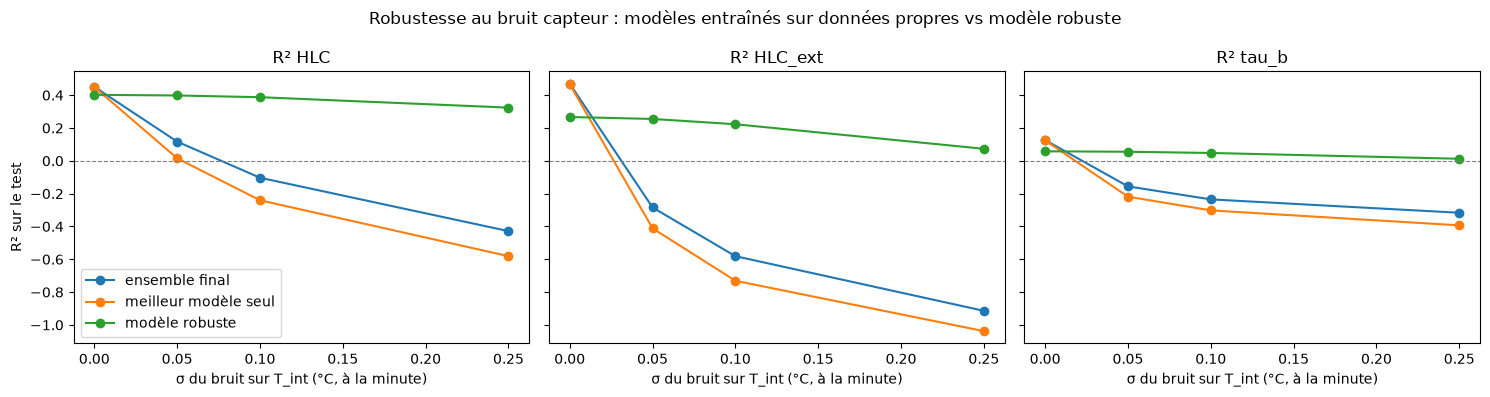

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Résultats sauvegardés par ce notebook (Kaggle ou copie locale dans results/results_full)
RES_DIR = next(p for p in [Path("/kaggle/working/results_full"), Path("../results/results_full"),
                           Path("results/results_full")] if p.exists())
rob = pd.read_csv(RES_DIR / "robustesse_bruit_final.csv", index_col=[0, 1])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ["HLC", "HLC_ext", "tau_b"]):
    for model, g in rob.groupby(level=0):
        ax.plot(g.index.get_level_values(1), g[col], marker="o", label=model)
    ax.axhline(0, color="grey", lw=0.8, ls="--")
    ax.set(title=f"R² {col}", xlabel="σ du bruit sur T_int (°C, à la minute)")
axes[0].set_ylabel("R² sur le test")
axes[0].legend()
fig.suptitle("Robustesse au bruit capteur : modèles entraînés sur données propres vs modèle robuste")
plt.tight_layout()
plt.show()

### 6.2 Limites et origine des erreurs

1. **Un plafond d'information, pas un défaut de modèle.** L'EDA montre que 94 à 98 % des variations de
   T_int s'expliquent par le programme de chauffe, et seulement 2 à 6 % par le bâtiment
   (`rapport.ipynb`, section 3.9). Toutes les pistes convergent vers le même niveau, environ 0,45 de R² HLC :
   architectures différentes, modèles plus grands, BiGRU, modèles résiduels, paramétrisation B,
   ensembles de 13 modèles (phases A2, A3 et section 5.1). La limite vient de l'information contenue dans
   8 h de mesure, pas de l'architecture.
2. **Pourquoi les τ restent difficiles** (R² de 0.09 à 0.26) :
   - **fenêtre trop courte** : en 8 h, on n'observe que 1 − e^(−8/τ) de la réponse lente, soit environ
     52 %, 23 % et 15 % selon le τ ;
   - **état initial inconnu** : la chaleur stockée dans les parois au début de la mesure produit une dérive
     de T_int qui se confond avec la réponse au chauffage ;
   - **capacité non observée** : τ ≈ C/HLC, et C ne se lit que dans la dynamique lente, justement
     tronquée par la fenêtre.

   Les τ prédits donnent un **ordre de grandeur** (15 à 18 % d'erreur relative), pas une mesure fiable.
3. **Régression vers la moyenne.** Comme tout estimateur sous incertitude, le modèle sous-estime les
   bâtiments très déperditifs et surestime les très isolés. Lors d'un diagnostic, il faut donc
   interpréter les valeurs extrêmes avec prudence. Voir la figure des résidus de l'annexe A2
   (`results/results_dl/residus_dl.png`).
4. **HLC_mit moins bien prédit que HLC_ext** (0.29 contre 0.47). Les échanges avec les locaux voisins
   dépendent d'une température mitoyenne que T_int et U ne renseignent qu'indirectement.
5. **Domaine de validité.** Le modèle est appris sur un seul bâtiment type (« quentin_house »), perturbé
   à ±60 % par Monte Carlo, avec des excitations PRBS. Sa validité hors de ce domaine (autre typologie,
   occupation réelle, apports solaires) n'est pas démontrée.

### 6.3 Sauvegarde des modèles livrés

Deux fichiers sont produits ; ils se rechargent avec `coenergy.final_model.FinalModel.load` :
- `modele_final.joblib` : l'ensemble pondéré des 8 réseaux (meilleure performance sur données propres) ;
- `modele_robuste.joblib` : le modèle entraîné avec bruit capteur (recommandé sur données réelles).

Chaque fichier contient les poids PyTorch, la normalisation des entrées, la transformation des cibles et
le pas de temps de chaque membre. Il prend en entrée les séries T_int et U brutes, à la minute.

Les deux cellules qui suivent la sauvegarde s'exécutent **en local**, sans GPU ni données : elles rechargent
les modèles livrés depuis `results/results_full/` avec le module `coenergy.final_model`.

In [ ]:
bundle = {"labels": list(LABELS), "input_dt_minutes": 1.0, "feature_sets": list(FEATURE_SETS), "raw_pool": 2,
          "members": [(MEMBERS[n][0], MEMBERS[n][1]) for n in FINAL_NAMES],
          "names": FINAL_NAMES, "combiner": COMB}
joblib.dump(bundle, OUT / "modele_final.joblib")
if robust_name:
    joblib.dump({**bundle, "members": [MEMBERS[robust_name]], "names": [robust_name], "combiner": None},
                OUT / "modele_robuste.joblib")
json.dump({"ensemble": BEST_LABEL, "membres": FINAL_NAMES, "robuste": robust_name,
           "duree_h": round((time.time() - START) / 3600, 2)},
          open(OUT / "selection_final.json", "w"), indent=1)
print("Fichiers :", sorted(p.name for p in OUT.iterdir()))
if (OUT / "erreurs.log").exists():
    print("\n Erreurs rencontrées :\n", open(OUT / "erreurs.log").read()[:3000])

In [2]:
from pathlib import Path
from coenergy.final_model import FinalModel

RES_DIR = next(p for p in [Path("../results/results_full"), Path("results/results_full")] if p.exists())
for name in ("modele_final.joblib", "modele_robuste.joblib"):
    m = FinalModel.load(RES_DIR / name)
    steps = sorted({f for f, _ in m.members})
    print(f"{name} : {len(m.members)} réseau(x) PyTorch, pas de temps {steps} min")
    print("   membres :", ", ".join(m.names))

modele_final.joblib : 8 réseau(x) PyTorch, pas de temps [2, 5] min
   membres : full2_g42, full2_B, res2_g42_10batchs, nuit_optuna_best_graine2024, nuit_optuna_best, nuit_cnn_gru, nuit_optuna_best_graine7, nuit_tcn
modele_robuste.joblib : 1 réseau(x) PyTorch, pas de temps [2] min
   membres : full2_robuste


In [3]:
# Démonstration de l'interface sur 3 séries factices de 8 h à la minute (480 points) :
# vérifie le format d'entrée et de sortie et la contrainte HLC = Hb_mit + Hb_ext, pas la précision.
import numpy as np

rng = np.random.default_rng(0)
U = np.repeat((rng.random((3, 16)) > 0.5) * 7000.0, 30, axis=1)    # créneaux de 30 min, 0 ou 7 000 W
T = 24.62 + np.cumsum(U / 7000 * 0.004 - 0.001, axis=1)           # température intérieure factice (°C)
pred = FinalModel.load(RES_DIR / "modele_final.joblib").predict(T, U)
display(pred.round(2))
print("HLC = Hb_mit + Hb_ext :", np.allclose(pred["HLC"], pred["HLC_mit"] + pred["HLC_ext"], rtol=1e-4))

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
0,239.41,128.99,110.42,54.84,15.90,37.66
1,224.14,122.06,102.08,58.94,17.21,40.59
2,287.03,133.36,153.67,45.72,11.85,30.30


HLC = Hb_mit + Hb_ext : True


## 7. Conclusion et recommandations

### 7.1 Ce qui a été obtenu
- Un **modèle PyTorch multi-indicateurs** (ensemble de CNN-GRU) qui prédit HLC, Hb_mit, Hb_ext et les trois
  constantes de temps à partir de 8 h de T_int et U, avec **HLC = Hb_mit + Hb_ext garanti par construction**.
- **R² HLC = 0.45** (erreur relative de 8 %), **confirmé sur deux jeux de test indépendants**. C'est
  +0.10 par rapport au meilleur modèle non neuronal, sans fuite de données et avec un test évalué une
  seule fois.
- Un **modèle robuste** dont la performance reste stable jusqu'à 0,25 °C de bruit capteur.

### 7.2 Ce que montre l'analyse
- La performance est limitée par **l'information contenue dans la mesure**, pas par le modèle :
  architectures, paramétrisations et ensembles convergent tous vers le même plafond.
- Les **τ** ne sont accessibles qu'en ordre de grandeur sur une fenêtre de 8 h.
- Un modèle entraîné sur données simulées parfaites **n'est pas utilisable tel quel** sur le terrain :
  la robustesse au bruit doit faire partie de l'entraînement.

### 7.3 Recommandations
**Pour le protocole de mesure** (d'après l'analyse des erreurs par segment de l'annexe A2,
`results/results_dl/segment_*.csv`) :
1. commencer par **1 à 3 h sans chauffage** pour observer la dérive libre et renseigner l'état initial
   des parois ;
2. utiliser des **paliers de chauffe longs** plutôt que des créneaux courts ;
3. **allonger la mesure au-delà de 8 h** quand c'est possible : c'est le levier principal pour τ_b et τ_∞ ;
4. **mesurer la température extérieure et mitoyenne** pour mieux séparer HLC_ext et HLC_mit.

**Pour le modèle** :
1. déployer le **modèle robuste**, avec un bruit d'entraînement calé sur la précision réelle du capteur ;
2. donner **en entrée** la durée de mesure et T_ext quand elles seront disponibles ;
3. ajouter une **estimation d'incertitude** (ensembles ou régression quantile), pour signaler les
   bâtiments dont le diagnostic est peu fiable ;
4. valider sur **des mesures réelles** et d'autres typologies de bâtiments avant tout usage opérationnel.